# Synthetic data with smaller and smaller fluct. time scale


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import copy

import os
%config InlineBackend.figure_format ='retina'

%load_ext autoreload
%autoreload 2

import sys
sys.path.insert(0, "../../")

from RealTrace_paper_analysis.plotting_src.read_ggp_run import * # you might need to change these two line, such that you can use read ggp_run
from RealTrace_paper_analysis.simulations.cells_simulation import * # you might need to change these two line, such that you can use read ggp_run

from RealTrace_paper_analysis.plotting_src.cells_utils import *
from RealTrace_paper_analysis.plotting_src.read_utils import *
from RealTrace_paper_analysis.plotting_src.header_settings import *

from RealTrace_paper_analysis.plotting_src.naive_rates import *

from mpl_toolkits.axes_grid1.inset_locator import (inset_axes, InsetPosition,
                                                  mark_inset)
import matplotlib
%config InlineBackend.figure_format ='retina'


/Users/bjoern/mother_machine/RealTrace_figure_notebooks/nb_figures_for_ggp_paper/../../RealTrace_paper_analysis/plotting_src/header_settings.py:8: UserWarning: A NumPy version >=1.22.4 and <2.3.0 is required for this version of SciPy (detected version 1.21.0)
  import scipy.stats


header_setting.py: using old naming


## Parameter estimation for random parameters


In [2]:

base_dir =  "../../data_realtrace_paper/vary_fluctuations_scale_simulations" 
data_set_name = "vary_fluctuations_scale_simulations_{:d}"


In [3]:
def get_ref(file_path):
    return os.path.join( file_path, "parameters_simulation.txt")


In [4]:
data_set_dir = os.path.join(base_dir,  data_set_name)
data_set_dirs = []
for ds in [data_set_dir.format(i,i) for i in range(100)]:
    if not os.path.exists(ds):
        continue
    if len(find_files_in_outs(ds, "final.csv"))>0:
        data_set_dirs.append(ds)
    else:
        print(ds)
        pass
# len(data_set_dirs)
# data_set_dir.format(0,0)

In [5]:
def exent_parameter_settings(ps):
    # add dummy "error" if not optimized
    for key in ps.keys():
        if len(ps[key]) == 2:
            ps[key].append(0)

    for rate in ["lambda", "q"]:
        std = np.sqrt(ps["var_"+rate][1]/(2.*ps["gamma_"+rate][1]))
        std_err2 = (1/2. * 1/np.sqrt( ps["var_"+rate][1]*ps["gamma_"+rate][1]) * ps["var_"+rate][2])**2 + \
                        (1/2. * np.sqrt(ps["var_"+rate][1]/2.) * ps["gamma_"+rate][1]**(-3/2.)* ps["gamma_"+rate][2])**2
        ps["std_"+rate] = ["derived", std, np.sqrt(std_err2)]

    for rate in ["lambda", "q"]:
        sigma = np.sqrt(ps["var_"+rate][1])
        ps["sigma_"+rate] = ["derived", sigma, None]
        
    for xg in ["dx", "dg"]:
        sigma = np.sqrt(ps["var_"+xg][1])
        ps["sigma_"+xg] = ["derived", sigma, None]
        
    for xg in ["x", "g"]:
        sigma = np.sqrt(ps["var_"+xg][1])
        sigma_err = 1/np.sqrt(ps["var_"+xg][1]) * ps["var_"+xg][2]
        ps["sigma_"+xg] = ["derived", sigma, sigma_err]
        
    return ps

/Users/bjoern/mother_machine/RealTrace_figure_notebooks/nb_figures_for_ggp_paper/../../RealTrace_paper_analysis/plotting_src/read_utils.py:244: RuntimeWarning: invalid value encountered in sqrt
  param_error = np.sqrt(np.array(line.strip().split(',')[1:]).astype(float))


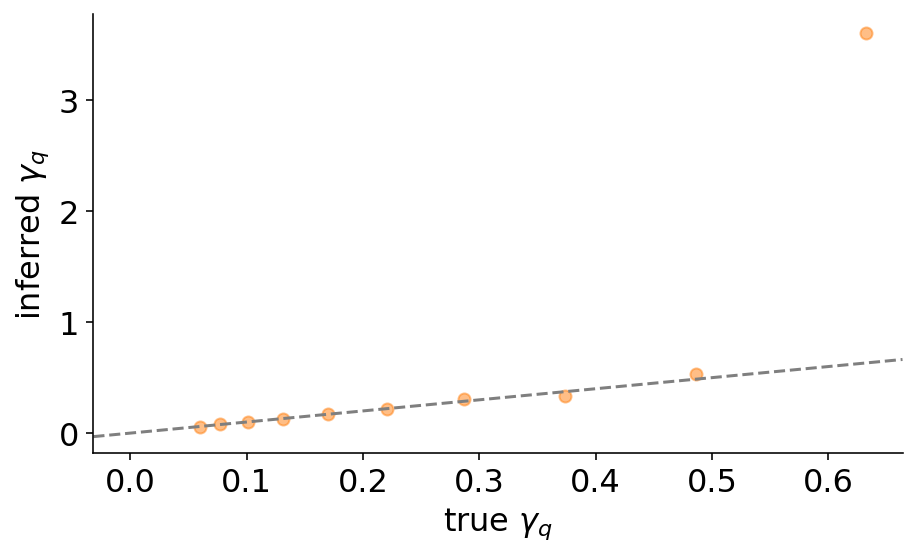

In [6]:
def plot_true_vs_inferred(data_set_dirs, 
                        parameter_name,
                        title=None,
                        all_parameter_names=None, 
                        err_bar_index=0, ylim=[None, None],
                        plot_file=None):

    
    fig = plt.figure(figsize=(HALF_SIZE,FULL_HEIGHT))
    ax = fig.add_subplot()
    if title!=None:
        ax.set_title(title)
    for a in [ax]:
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)
        a.spines['right'].set_color('none')
        a.spines['top'].set_color('none')


    init_coll = []

    for i, data_set_dir in enumerate(data_set_dirs):
        inferred = read_header(find_files_in_outs(data_set_dir)[0], epsilon_err=0.005)
        inferred = exent_parameter_settings(inferred)

        true = read_parameter_file(get_ref(data_set_dir))
        true = exent_parameter_settings(true)

        inferred[parameter_name][1]
        true[parameter_name][1]
        
        
        ax.scatter(true[parameter_name][1], inferred[parameter_name][1], 
                   color="tab:orange", alpha=0.5)
        
        
        
    ax.axline( (0,0), slope=1, color="tab:grey", ls='--' )
    ax.set_xlabel("true "+parameter_names_unit_free[parameter_name])
    ax.set_ylabel("inferred "+parameter_names_unit_free[parameter_name])
    
    plt.tight_layout()
    if plot_file!=None:
        plt.savefig(plot_file,bbox_inches='tight')
    plt.show()

plot_true_vs_inferred(data_set_dirs, "gamma_q",
                             all_parameter_names=parameter_names_unit_free)
                             # plot_file=os.path.join("../../figures_for_method_paper/supp/supp_parameters/", "parameters_init.pdf"))


## Prediction 


In [7]:
data_set_dir = os.path.join(base_dir,  data_set_name)
prediction_file_coll = []
simulation_file_coll = []
sim_paramas = []
true_params = []
for ds in [data_set_dir.format(i,i) for i in range(10)]:
    simulation_file_coll.append(find_files(ds, ".csv")[0])
    sim_paramas.append(find_files(ds, "simulation.txt")[0])
    prediction_file_coll.append(find_files_in_outs(ds, "prediction.csv")[0])
    true_params.append(exent_parameter_settings(read_parameter_file(sim_paramas[-1])))

In [8]:
def get_dev_stats(simulation_file_coll, prediction_file_coll):
    rel_err = []
    z_stat_mean = [] 
    z_stat_std = []
    
    for i, _ in enumerate(prediction_file_coll[:]):
        
        indata = pd.read_csv(simulation_file_coll[i], dtype={"parent_id":str, "cell_id":str})
        
        prediction = pd.read_csv(prediction_file_coll[i], skiprows=header_lines(prediction_file_coll[i]), 
                                 dtype={"parent_id":str, "cell_id":str})

        cells_true = df2cells(indata, time="time_min", log_length="log_length", gfp="gfp", 
                                    cell_id="cell_id", parent_id="parent_id", 
                                    lt="lt", qt="qt")

        cells_prediction = ggp_df2cells(prediction, time="time", log_length="mean_x", gfp="mean_g", 
                                    cell_id="cell_id", parent_id="parent_id", 
                                    lt="mean_l", qt="mean_q")
        
        true_qs = np.concatenate([cell.qt for cell in cells_true])
        pred_qs = np.concatenate([cell.qt for cell in cells_prediction])
        cov_qqs = np.concatenate([cell.cov_qq for cell in cells_prediction])

        # STATS
        sq_err = np.mean((pred_qs-true_qs)**2)
        rel_err.append(np.sqrt(sq_err)/np.mean(true_qs))
        
        z_stat = (pred_qs-true_qs)/np.sqrt(cov_qqs)
        
        z_stat_mean.append(np.mean(z_stat))
        z_stat_std.append(np.std(z_stat))
        print(i, end=" ")
    return rel_err, z_stat_mean, z_stat_std
    
rel_err, z_stat_mean, z_stat_std = get_dev_stats(simulation_file_coll, prediction_file_coll)




0 1 2 3 4 5 6 7 8 9 

/Users/bjoern/mother_machine/RealTrace_figure_notebooks/nb_figures_for_ggp_paper/../../RealTrace_paper_analysis/plotting_src/read_utils.py:244: RuntimeWarning: invalid value encountered in sqrt
  param_error = np.sqrt(np.array(line.strip().split(',')[1:]).astype(float))


16.778523489932887
12.919896640826874
9.900990099009901
7.633587786259541
5.88235294117647
4.524886877828054
3.4843205574912894
2.6737967914438503
2.05761316872428
1.5822784810126582


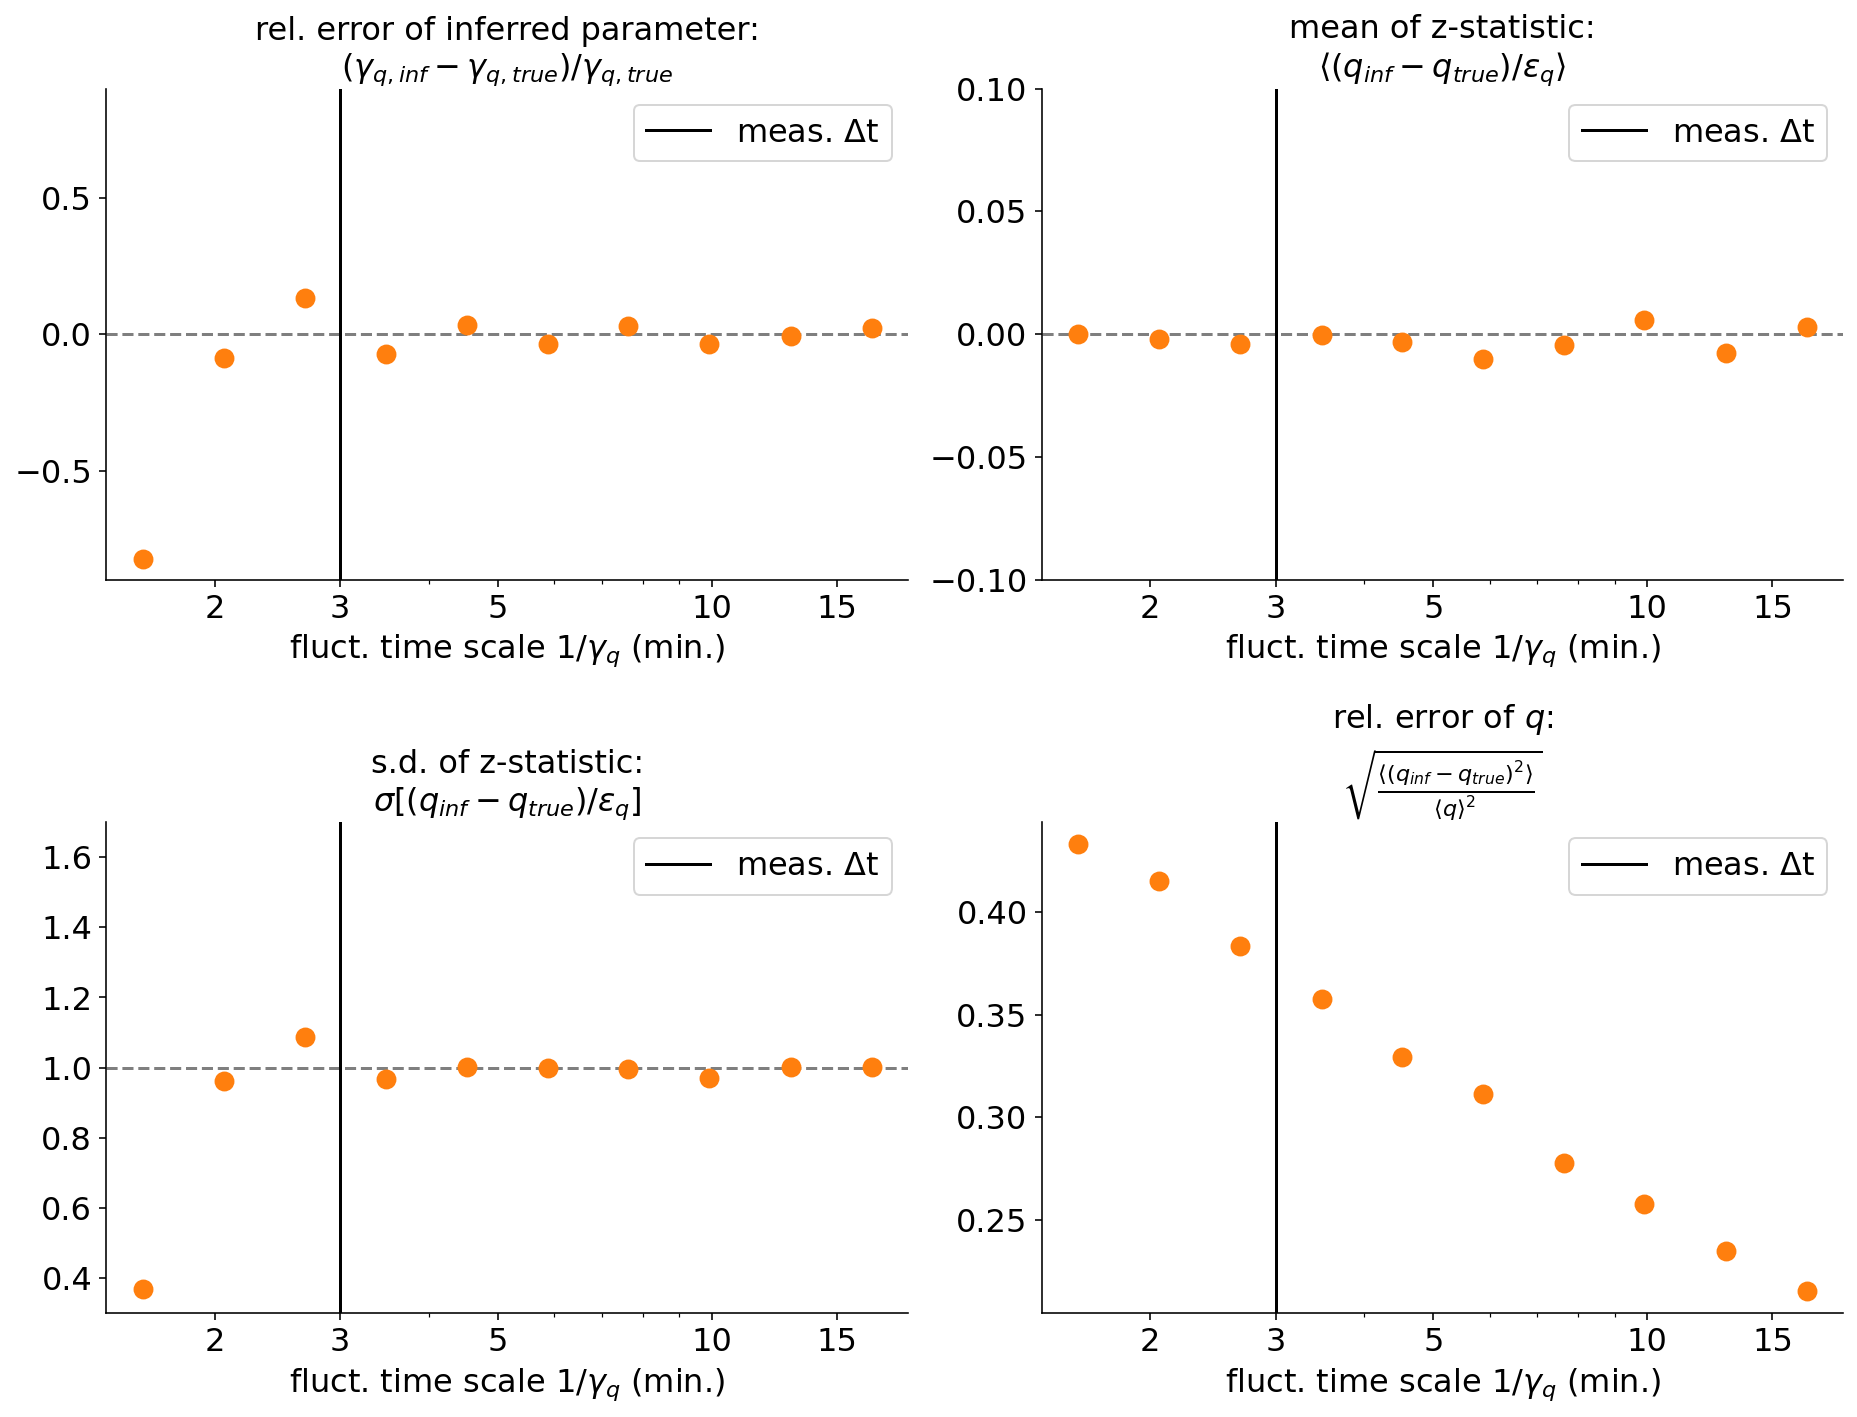

In [12]:

        
def plot_all_simulations_prediciton(rel_err, 
                                    z_stat_mean, 
                                    z_stat_std, 
                                    sim_params, 
                                    data_set_dirs,
                                    all_parameter_names,
                                    plot_file=None):
    
    fig, ax = plt.subplots(2, 2, figsize=(FULL_SIZE, FULL_HEIGHT*2.5))
    ax = ax.ravel()
    for a in ax:
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)
        a.spines['right'].set_color('none')
        a.spines['top'].set_color('none')

        a.axvline(3, color="black", ls="-", label=r"meas. $\Delta$t")
        # a.set_xlim(0, 20)

        a.set_xscale("log")
        a.set_xlabel(r"fluct. time scale 1/$\gamma_q$ (min.)" )
        ticks = [1,2,3,5,10,15]
        a.set_xticks(ticks, ticks)

   #### INFER PARAM #####
    a = ax[0]
    a.set_ylim(-0.9, 0.9)
    a.axhline(0, color="tab:grey", ls="--", zorder=-1)
    a.set_title("rel. error of inferred parameter:\n" +r"$(\gamma_{q, inf}-\gamma_{q,true})/\gamma_{q, true}$")
    
    for i, data_set_dir in enumerate(data_set_dirs):
        inferred = exent_parameter_settings(read_header(find_files_in_outs(data_set_dir)[0], epsilon_err=0.005))
        true = exent_parameter_settings(read_parameter_file(get_ref(data_set_dir)))

        true_scale = 1/true["gamma_q"][1]
        infer_scale = 1./inferred["gamma_q"][1]
        
        a.scatter(true_scale, (infer_scale-true_scale)/true_scale, 
                   color="tab:orange",s=80)


        
    #### MEAN #####
    a = ax[1]
    a.set_ylim(-0.1, 0.1)
    a.set_title("mean of z-statistic:\n" +r"$\langle(q_{inf}-q_{true})/\epsilon_q\rangle$")
    a.axhline(0, color="tab:grey", ls="--", zorder=-1)
        
    for i in range(10):
        a.scatter(1/sim_params[i]["gamma_q"][1], z_stat_mean[i], color="tab:orange",s=80)
    
    
    #### STD #####
    a = ax[2]
    a.set_ylim(0.3, 1.7)
    a.axhline(1, color="tab:grey", ls="--", zorder=-1)
    a.set_title("s.d. of z-statistic:\n" +"$\sigma[(q_{inf}-q_{true})/\epsilon_q]$")
    for i in range(10):
        a.scatter(1/sim_params[i]["gamma_q"][1], z_stat_std[i], color="tab:orange", s=80)
            
    
    #### REL_ERR #####
    a = ax[3]
    a.set_title("rel. error of $q$:\n" + r"$\sqrt{\frac{ \langle (q_{inf}-q_{true})^2\rangle }{\langle q\rangle^2}} $ ")
    
    for i in range(10):
        print(1/sim_params[i]["gamma_q"][1])
        a.scatter(1/sim_params[i]["gamma_q"][1], rel_err[i], color="tab:orange", s=80)

    for a in ax:
        a.legend()

    plt.tight_layout()
    
    if plot_file!=None:
        plt.savefig(plot_file, bbox_inches='tight')
    plt.show()
    

plot_all_simulations_prediciton(rel_err, 
                                z_stat_mean, 
                                z_stat_std, 
                                true_params,
                                data_set_dirs, 
                                parameter_names_unit_free,
                                plot_file=os.path.join("../../figures_for_method_paper/supp/fluctuations_time_scale/", "fluctuations_time_scale.pdf"))
